# Gaussian Process Regression baseline

This notebook establishes a Gaussian Process Regression baseline for the `MONTHLY_RENT` target using the same processed parquet files and cleaning conventions as the other experiments.

Gaussian Processes scale cubically with the number of observations, so this baseline models the monthly mean rent rather than all 150,000 flat-level rows. The model uses time, trend, and annual seasonality features and produces both a forecast and uncertainty intervals.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

HERE=Path.cwd().resolve()
PROJECT_ROOT=next((p for p in [HERE,*HERE.parents] if (p/'final_report'/'data'/'train_features.parquet').exists()), HERE)
DATA_ROOT=PROJECT_ROOT/'final_report'/'data'
train=pd.read_parquet(DATA_ROOT/'train_features.parquet')
test=pd.read_parquet(DATA_ROOT/'test_features.parquet')
for frame in (train,test):
    frame['RENT_APPROVAL_DATE']=pd.to_datetime(frame['RENT_APPROVAL_DATE'])
    frame['ds']=frame['RENT_APPROVAL_DATE'].dt.to_period('M').dt.to_timestamp()
train['MONTHLY_RENT']=pd.to_numeric(train['MONTHLY_RENT'],errors='coerce')
clean=train.dropna(subset=['MONTHLY_RENT']).query('MONTHLY_RENT>0')
monthly=(clean.groupby('ds',as_index=False).agg(y=('MONTHLY_RENT','mean'),n=('MONTHLY_RENT','size')).sort_values('ds'))
print('Monthly observations:',len(monthly),'| period:',monthly.ds.min(),'to',monthly.ds.max())

Monthly observations: 51 | period: 2021-01-01 00:00:00 to 2025-03-01 00:00:00


## Feature representation

The Gaussian Process receives a continuous time index, annual sine/cosine seasonality, and a scaled trend. These features let the kernel express smooth long-term movement and recurring calendar effects.

Optimized kernel: 1.22**2 * Matern(length_scale=3.25, nu=1.5) + WhiteKernel(noise_level=1e-05)


/Users/marklim/ipykernel-env/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


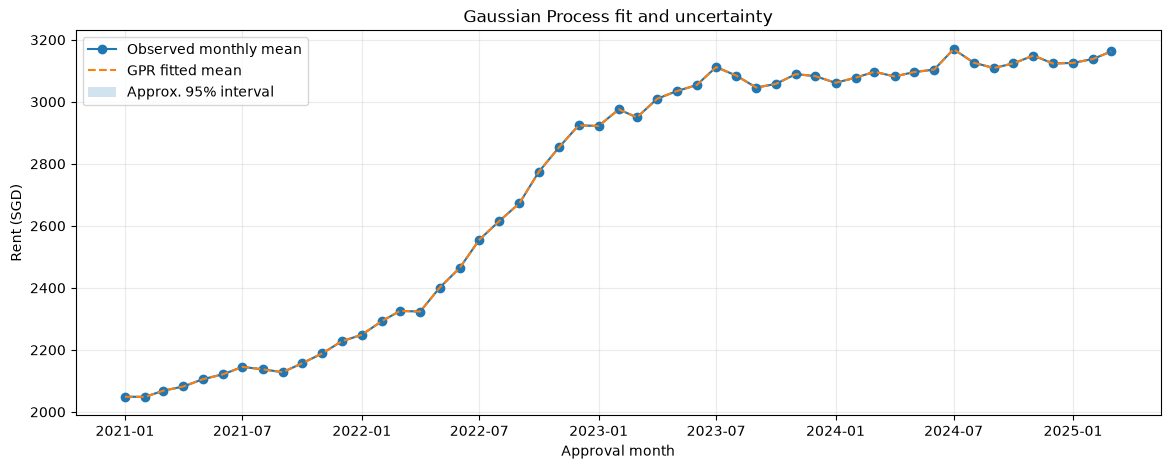

In [2]:
def time_features(frame):
    out=pd.DataFrame(index=frame.index)
    out['trend']=(frame.ds.dt.year-frame.ds.dt.year.min())*12+frame.ds.dt.month
    out['month_sin']=np.sin(2*np.pi*frame.ds.dt.month/12)
    out['month_cos']=np.cos(2*np.pi*frame.ds.dt.month/12)
    return out

X_raw=time_features(monthly)
x_scaler=StandardScaler(); X=x_scaler.fit_transform(X_raw)
y=monthly.y.to_numpy()

kernel=ConstantKernel(1.0,(1e-3,1e3))*Matern(length_scale=1.0,nu=1.5)+WhiteKernel(noise_level=0.1,noise_level_bounds=(1e-5,1e3))
gpr=GaussianProcessRegressor(kernel=kernel,normalize_y=True,n_restarts_optimizer=3,random_state=42)
gpr.fit(X,y)
mean,std=gpr.predict(X,return_std=True)
print('Optimized kernel:',gpr.kernel_)

plt.figure(figsize=(14,5)); plt.plot(monthly.ds,y,'o-',label='Observed monthly mean'); plt.plot(monthly.ds,mean,'--',label='GPR fitted mean'); plt.fill_between(monthly.ds,mean-1.96*std,mean+1.96*std,alpha=.2,label='Approx. 95% interval'); plt.title('Gaussian Process fit and uncertainty'); plt.xlabel('Approval month'); plt.ylabel('Rent (SGD)'); plt.legend(); plt.grid(alpha=.25); plt.show()

## Chronological validation

The final 12 months are divided into three forward validation blocks. The kernel is refit within each fold using only earlier months. Metrics are compared with a historical-mean baseline.

Corrected validation metrics: {'MAE': 122.62355680347942, 'RMSE': np.float64(137.87421544592402), 'R2': -28.9628395610882}


/Users/marklim/ipykernel-env/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/marklim/ipykernel-env/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/marklim/ipykernel-env/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


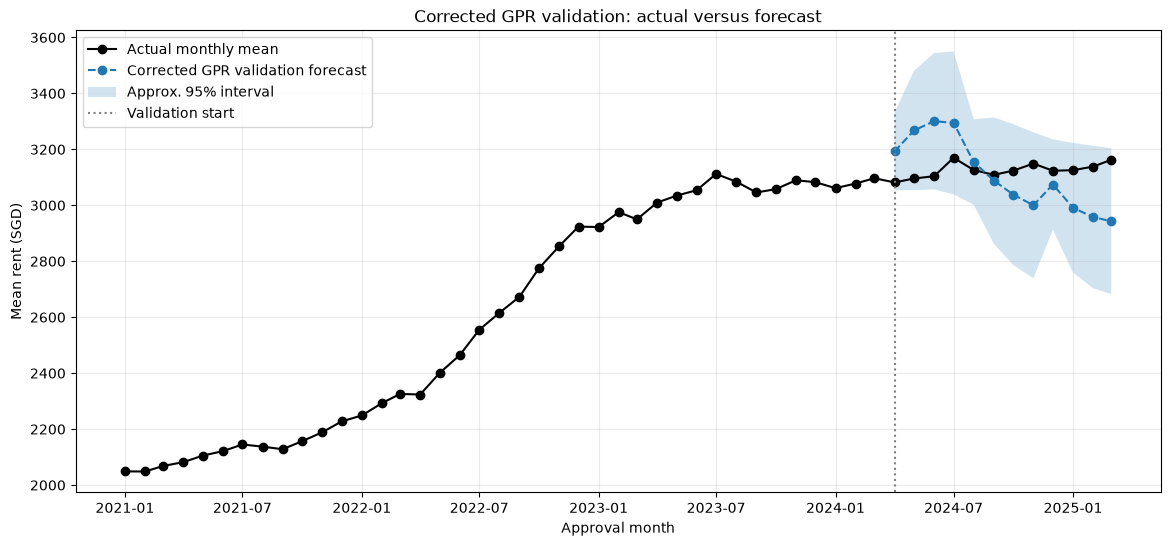

In [3]:
def time_features_global(frame, origin):
    out=pd.DataFrame(index=frame.index)
    out['trend']=(frame.ds-origin).dt.days/30.4375
    out['month_sin']=np.sin(2*np.pi*frame.ds.dt.month/12)
    out['month_cos']=np.cos(2*np.pi*frame.ds.dt.month/12)
    return out

def metrics(actual,pred):
    actual=np.asarray(actual,dtype=float); pred=np.asarray(pred,dtype=float)
    mask=np.isfinite(actual)&np.isfinite(pred)
    return {'MAE':mean_absolute_error(actual[mask],pred[mask]),'RMSE':np.sqrt(mean_squared_error(actual[mask],pred[mask])),'R2':r2_score(actual[mask],pred[mask]) if mask.sum()>=2 else np.nan}

origin=monthly.ds.min(); corrected_rows=[]
for fold,valid_months in enumerate(np.array_split(monthly.ds.iloc[-12:].to_numpy(),3),1):
    fit=monthly[monthly.ds<valid_months.min()].copy(); valid=monthly[monthly.ds.isin(valid_months)].copy()
    fold_scaler=StandardScaler(); fit_X=fold_scaler.fit_transform(time_features_global(fit,origin)); valid_X=fold_scaler.transform(time_features_global(valid,origin))
    kernel=ConstantKernel(1.0,(1e-3,1e3))*Matern(length_scale=1.0,nu=1.5)+WhiteKernel(noise_level=.1,noise_level_bounds=(1e-5,1e3))
    model=GaussianProcessRegressor(kernel=kernel,normalize_y=True,n_restarts_optimizer=2,random_state=fold); model.fit(fit_X,fit.y)
    pred,std=model.predict(valid_X,return_std=True)
    corrected_rows.append(pd.DataFrame({'ds':valid.ds,'actual':valid.y,'gpr':pred,'lower':pred-1.96*std,'upper':pred+1.96*std,'fold':fold}))
corrected_oof=pd.concat(corrected_rows,ignore_index=True); corrected_metrics=metrics(corrected_oof.actual,corrected_oof.gpr); print('Corrected validation metrics:',corrected_metrics)
plt.figure(figsize=(14,6)); plt.plot(monthly.ds,monthly.y,'o-',color='black',label='Actual monthly mean'); plt.plot(corrected_oof.ds,corrected_oof.gpr,'o--',label='Corrected GPR validation forecast'); plt.fill_between(corrected_oof.ds,corrected_oof.lower,corrected_oof.upper,alpha=.2,label='Approx. 95% interval'); plt.axvline(monthly.ds.iloc[-12],color='gray',linestyle=':',label='Validation start'); plt.title('Corrected GPR validation: actual versus forecast'); plt.xlabel('Approval month'); plt.ylabel('Mean rent (SGD)'); plt.legend(); plt.grid(alpha=.25); plt.show()

## Final forecast for the processed test horizon

The final GPR is refit on all monthly training observations and forecasts the unique months represented in the test parquet. The test target is not available, so these future predictions cannot be directly scored.

,ds,forecast,lower,upper
50,2025-03-01,3162.688355,3159.023951,3166.352759
51,2025-04-01,3077.796959,2902.177452,3253.416466
52,2025-05-01,3013.670968,2771.790216,3255.551719
53,2025-06-01,3008.436823,2747.681213,3269.192433
54,2025-07-01,3043.561263,2777.428158,3309.694367
55,2025-08-01,3049.040446,2781.245267,3316.835625
56,2025-09-01,3070.486033,2802.088395,3338.883671
57,2025-10-01,3113.794043,2845.045417,3382.542669
58,2025-11-01,3148.429376,2879.313623,3417.545128
59,2025-12-01,3156.380056,2886.851189,3425.908924


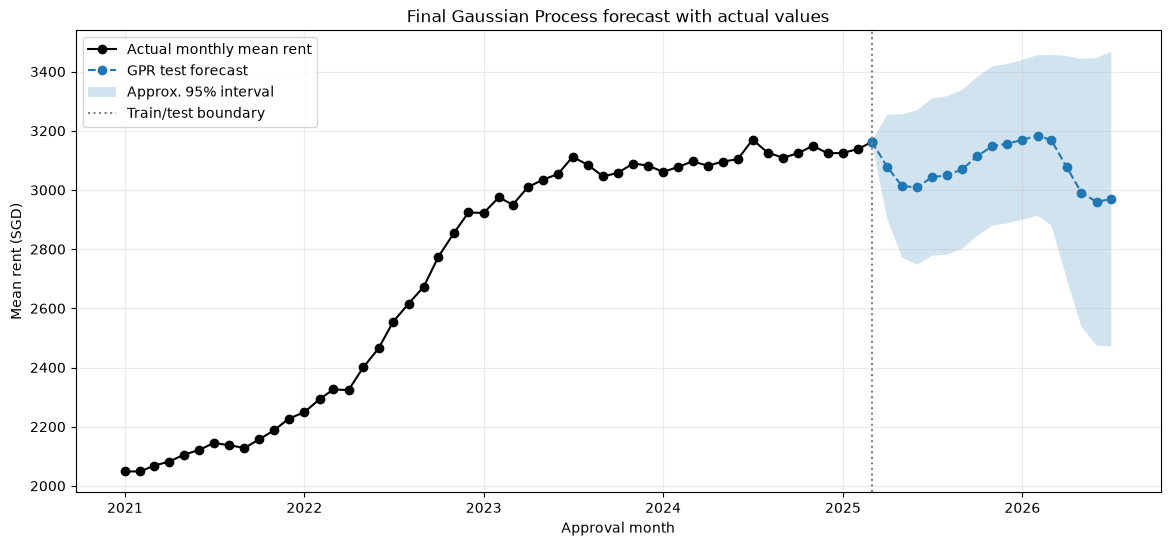

In [4]:
test_months=pd.DataFrame({'ds':sorted(test.ds.unique())})
future_index=pd.concat([monthly[['ds']],test_months]).drop_duplicates().sort_values('ds').reset_index(drop=True)
future_X=x_scaler.transform(time_features(future_index))
future_mean,future_std=gpr.predict(future_X,return_std=True)
future=pd.DataFrame({'ds':future_index.ds,'forecast':future_mean,'lower':future_mean-1.96*future_std,'upper':future_mean+1.96*future_std})
future=future[future.ds.isin(test_months.ds)].copy()
display(future)
plt.figure(figsize=(14,6)); plt.plot(monthly.ds,monthly.y,'o-',color='black',label='Actual monthly mean rent'); plt.plot(future.ds,future.forecast,'o--',label='GPR test forecast'); plt.fill_between(future.ds,future.lower,future.upper,alpha=.2,label='Approx. 95% interval'); plt.axvline(monthly.ds.max(),color='gray',linestyle=':',label='Train/test boundary'); plt.title('Final Gaussian Process forecast with actual values'); plt.xlabel('Approval month'); plt.ylabel('Mean rent (SGD)'); plt.legend(); plt.grid(alpha=.25); plt.show()
future.to_csv(DATA_ROOT/'gaussian_process_monthly_forecast.csv',index=False)

## Interpretation

This baseline captures smooth trend and annual seasonality while quantifying uncertainty. Its limitations are important: it models only the aggregate monthly series, the validation sample is small, and it does not use flat-level features. Later MLForecast and residual models can be compared against this baseline using the same chronological folds.

## Corrected validation metrics

Corrected out-of-fold metrics: {'MAE': 122.62355680347942, 'RMSE': np.float64(137.87421544592402), 'MAPE (%)': np.float64(3.9195488830766188), 'R2': -28.9628395610882}


/Users/marklim/ipykernel-env/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/marklim/ipykernel-env/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/marklim/ipykernel-env/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,ds,actual,forecast,lower,upper,fold
0,2024-04-01,3081.794024,3192.727554,3053.699888,3331.755219,1
1,2024-05-01,3095.840570,3267.675883,3054.243573,3481.108192,1
2,2024-06-01,3103.949186,3300.717324,3056.691805,3544.742842,1
3,2024-07-01,3169.898305,3294.504914,3039.261023,3549.748805,1
4,2024-08-01,3126.059301,3154.524020,3001.666553,3307.381486,2
5,2024-09-01,3108.928730,3088.490273,2862.511837,3314.468709,2
6,2024-10-01,3123.879459,3038.078682,2786.238004,3289.919360,2
7,2024-11-01,3149.154328,3000.003586,2739.141142,3260.866029,2
8,2024-12-01,3123.598757,3074.343274,2912.897343,3235.789204,3
9,2025-01-01,3125.447387,2991.193195,2759.514768,3222.871621,3


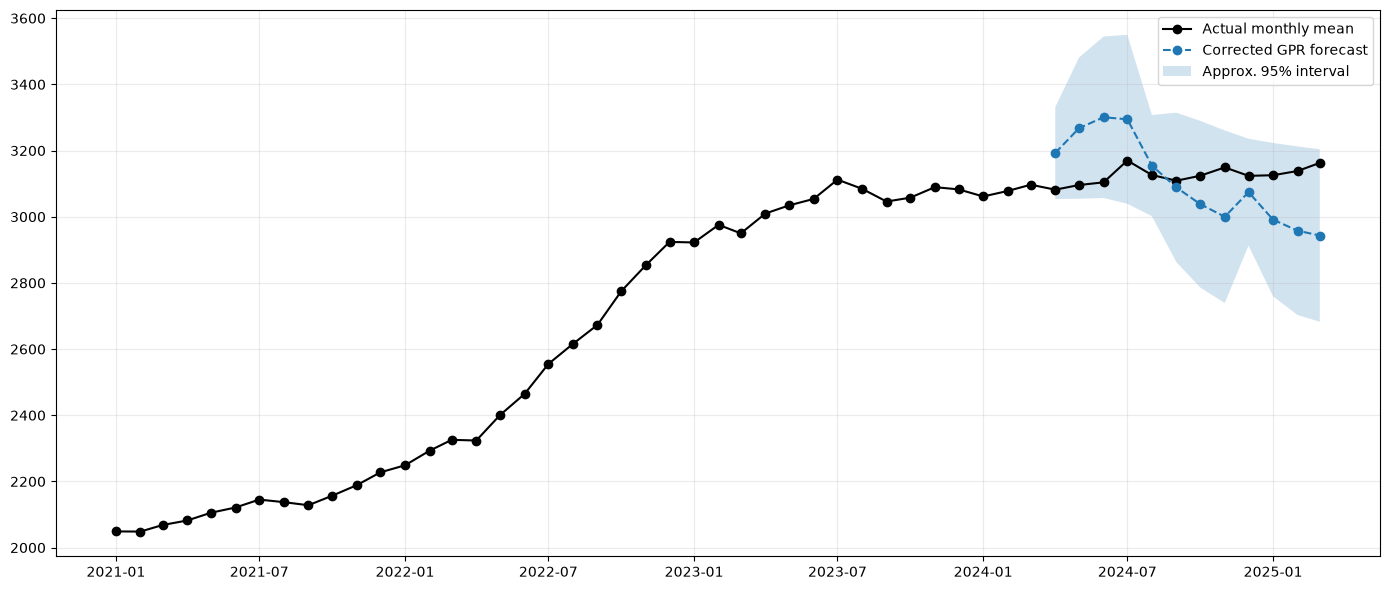

In [5]:
def corrected_metrics(actual,pred):
    return {'MAE':mean_absolute_error(actual,pred),'RMSE':np.sqrt(mean_squared_error(actual,pred)),'MAPE (%)':np.mean(np.abs((actual-pred)/actual))*100,'R2':r2_score(actual,pred)}
origin=monthly.ds.min(); corrected_rows=[]
for fold,valid_months in enumerate(np.array_split(monthly.ds.iloc[-12:].to_numpy(),3),1):
    fit=monthly[monthly.ds<valid_months.min()]; valid=monthly[monthly.ds.isin(valid_months)]; fold_scaler=StandardScaler(); fit_X=fold_scaler.fit_transform(time_features_global(fit,origin)); valid_X=fold_scaler.transform(time_features_global(valid,origin))
    kernel=ConstantKernel(1.0,(1e-3,1e3))*Matern(length_scale=1.0,nu=1.5)+WhiteKernel(noise_level=.1,noise_level_bounds=(1e-5,1e3)); model=GaussianProcessRegressor(kernel=kernel,normalize_y=True,n_restarts_optimizer=2,random_state=fold); model.fit(fit_X,fit.y); pred,std=model.predict(valid_X,return_std=True)
    corrected_rows.append(pd.DataFrame({'ds':valid.ds.to_numpy(),'actual':valid.y.to_numpy(),'forecast':pred,'lower':pred-1.96*std,'upper':pred+1.96*std,'fold':fold}))
corrected_oof=pd.concat(corrected_rows,ignore_index=True).sort_values('ds'); print('Corrected out-of-fold metrics:',corrected_metrics(corrected_oof.actual,corrected_oof.forecast)); display(corrected_oof)
plt.figure(figsize=(14,6)); plt.plot(monthly.ds,monthly.y,'o-',color='black',label='Actual monthly mean'); plt.plot(corrected_oof.ds,corrected_oof.forecast,'o--',label='Corrected GPR forecast'); plt.fill_between(corrected_oof.ds,corrected_oof.lower,corrected_oof.upper,alpha=.2,label='Approx. 95% interval'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

## GPR experiment using 2023 onward

This appended section repeats the corrected Gaussian Process experiment using only monthly observations from January 2023 onward. Earlier cells are unchanged.

2023-onward fold metrics


,fold,model,MAE,RMSE,MAPE (%),R2
0,1,GPR 2023 onward,33.787758,40.487982,1.072041,-1.486849
1,2,GPR 2023 onward,19.956658,23.088142,0.635757,-2.713326
2,3,GPR 2023 onward,20.453704,26.600628,0.648305,-1.962664


2023-onward mean metrics


,Mean
MAE,24.732707
RMSE,30.058917
MAPE (%),0.785368
R2,-2.054280


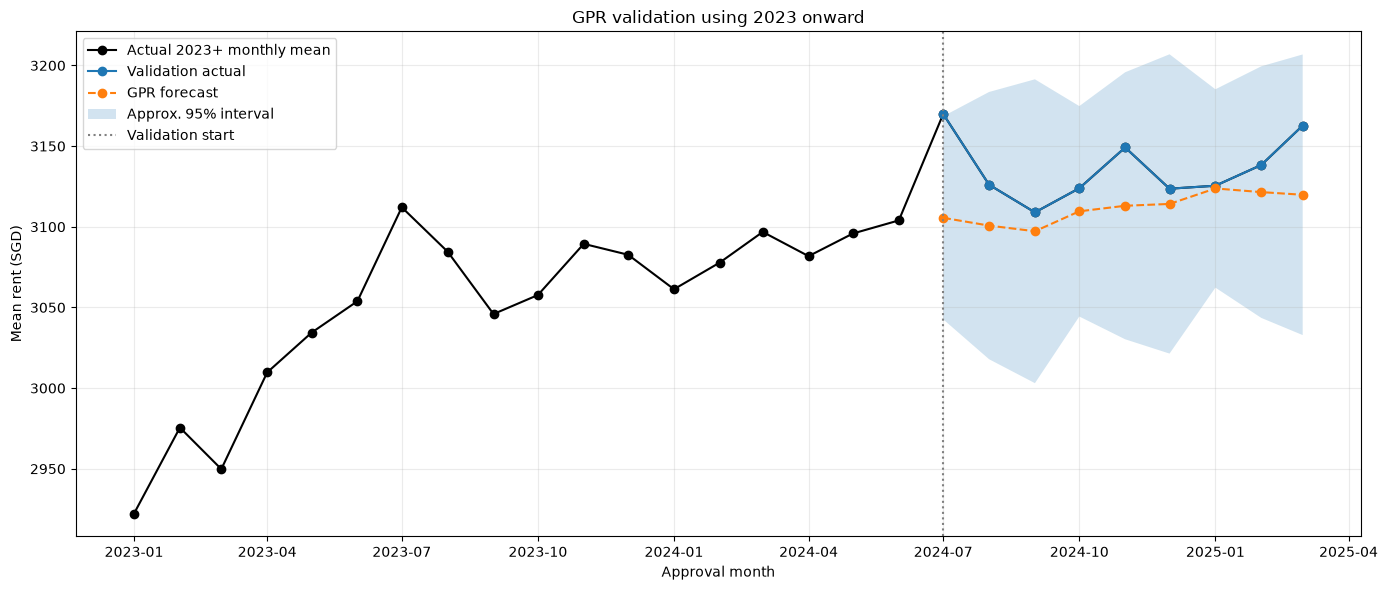

In [6]:
EXPERIMENT_START = pd.Timestamp('2023-01-01')
FIT_END = pd.Timestamp('2024-03-01')
VALID_START = pd.Timestamp('2024-04-01')
VALID_END = pd.Timestamp('2025-03-01')
HOLDOUT_START = pd.Timestamp('2099-01-01')
HOLDOUT_END = pd.Timestamp('2099-12-01')
# 2023-onward experiment: exclude all monthly observations before 2023.
recent_monthly=monthly[monthly.ds>=EXPERIMENT_START].reset_index(drop=True)
recent_validation_months = recent_monthly.loc[recent_monthly.ds.between(VALID_START, VALID_END), 'ds'].to_numpy()
recent_origin=recent_monthly.ds.min(); recent_rows=[]; recent_predictions=[]
for fold,valid_months in enumerate(np.array_split(recent_validation_months,3),1):
    fit=recent_monthly[recent_monthly.ds<valid_months.min()]; valid=recent_monthly[recent_monthly.ds.isin(valid_months)]
    fold_scaler=StandardScaler(); fit_X=fold_scaler.fit_transform(time_features_global(fit,recent_origin)); valid_X=fold_scaler.transform(time_features_global(valid,recent_origin))
    kernel=ConstantKernel(1.0,(1e-3,1e3))*Matern(length_scale=1.0,nu=1.5)+WhiteKernel(noise_level=.1,noise_level_bounds=(1e-5,1e3))
    model=GaussianProcessRegressor(kernel=kernel,normalize_y=True,n_restarts_optimizer=2,random_state=fold); model.fit(fit_X,fit.y); pred,std=model.predict(valid_X,return_std=True)
    actual=valid.y.to_numpy(); recent_rows.append({'fold':fold,'model':'GPR 2023 onward',**corrected_metrics(actual,pred)}); recent_predictions.append(pd.DataFrame({'ds':valid.ds.to_numpy(),'actual':actual,'forecast':pred,'lower':pred-1.96*std,'upper':pred+1.96*std,'fold':fold}))
recent_oof=pd.concat(recent_predictions,ignore_index=True).sort_values('ds'); recent_metrics=pd.DataFrame(recent_rows)
print('2023-onward fold metrics'); display(recent_metrics); print('2023-onward mean metrics'); display(recent_metrics[['MAE','RMSE','MAPE (%)','R2']].mean().to_frame('Mean'))
plt.figure(figsize=(14,6)); plt.plot(recent_monthly.ds,recent_monthly.y,'o-',color='black',label='Actual 2023+ monthly mean'); plt.plot(recent_oof.ds,recent_oof.actual,'o-',label='Validation actual'); plt.plot(recent_oof.ds,recent_oof.forecast,'o--',label='GPR forecast'); plt.fill_between(recent_oof.ds,recent_oof.lower,recent_oof.upper,alpha=.2,label='Approx. 95% interval'); plt.axvline(VALID_START,color='gray',linestyle=':',label='Validation start'); plt.title('GPR validation using explicit Mar 2024–Apr 2025 window'); plt.xlabel('Approval month'); plt.ylabel('Mean rent (SGD)'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

## Two-stage 2023-onward GPR plus residual model

In [7]:
from xgboost import XGBRegressor

# Build residual features using the same property/accessibility inputs as
# time_series_plus_residual_model.ipynb.
access_path=DATA_ROOT/'original_dataset'/'auxiliary'/'hdb_features_with_accessibility.csv'
access=pd.read_csv(access_path)
access_cols=['ADDRESS_KEY','MRT_DISTANCE_KM','BUS_STOP_DISTANCE_KM','MRT_WITHIN_250M','BUS_STOPS_WITHIN_250M','MRT_WITHIN_750M','BUS_STOPS_WITHIN_750M','SCHOOL_DISTANCE_KM','mean_travel_time_min','median_travel_time_min','cbd_travel_time_min','education_access_time_min']
access=access[[c for c in access_cols if c in access.columns]].drop_duplicates('ADDRESS_KEY')
# Keep the complete training set for the full-period experiment below, but
# restrict every input to this branch to January 2023 onward.
recent_rows=train[train.ds>=EXPERIMENT_START].copy().merge(access,on='ADDRESS_KEY',how='left',validate='many_to_one')
test_with_access=test.copy().merge(access,on='ADDRESS_KEY',how='left',validate='many_to_one')
excluded={'MONTHLY_RENT','RENT_APPROVAL_DATE','ds','ROW_ID','ADDRESS_KEY'}
feature_cols=[c for c in recent_rows.columns if c not in excluded and not c.lower().startswith(('macro_','coe_','stock_')) and not pd.api.types.is_datetime64_any_dtype(recent_rows[c])]
combined=pd.concat([recent_rows[feature_cols],test_with_access[feature_cols]],ignore_index=True)
X_all=pd.get_dummies(combined,dummy_na=True).replace([np.inf,-np.inf],np.nan).fillna(-999)
X_all.columns=[str(c).replace('[','(').replace(']',')').replace('<','_').replace('>','_').replace(' ','_').replace(':','_') for c in X_all.columns]
seen={}
unique_columns=[]
for name in X_all.columns:
    count=seen.get(name,0); unique_columns.append(name if count==0 else f'{name}_{count}'); seen[name]=count+1
X_all.columns=unique_columns
Xr=X_all.iloc[:len(recent_rows)].copy().reset_index(drop=True)
Xt=X_all.iloc[len(recent_rows):].copy().reset_index(drop=True)
recent_rows=recent_rows.reset_index(drop=True); test_with_access=test_with_access.reset_index(drop=True)
def fit_gpr(fit,predict,origin):
    sc=StandardScaler(); A=sc.fit_transform(time_features_global(fit,origin)); B=sc.transform(time_features_global(predict,origin)); k=ConstantKernel(1.0,(1e-3,1e3))*Matern(length_scale=1.0,nu=1.5)+WhiteKernel(noise_level=.1,noise_level_bounds=(1e-5,1e3)); m=GaussianProcessRegressor(kernel=k,normalize_y=True,n_restarts_optimizer=2,random_state=42); m.fit(A,fit.y); return m.predict(B)
row_scores=[]; folds=np.array_split(recent_validation_months,3)
for fold,valid_months in enumerate(folds,1):
    fit_m=recent_monthly[recent_monthly.ds<valid_months.min()]; valid_m=recent_monthly[recent_monthly.ds.isin(valid_months)]; base=fit_gpr(fit_m,valid_m,recent_origin); base_map=dict(zip(valid_m.ds,base)); fit_r=recent_rows[recent_rows.ds<valid_months.min()].copy(); valid_r=recent_rows[recent_rows.ds.isin(valid_months)].copy(); fit_r['stage1']=fit_r.ds.map(dict(zip(fit_m.ds,fit_m.y))).fillna(fit_r.MONTHLY_RENT.mean()); valid_r['stage1']=valid_r.ds.map(base_map)
    residual_model=XGBRegressor(n_estimators=300,max_depth=3,learning_rate=.03,subsample=.8,colsample_bytree=.8,reg_lambda=5,objective='reg:squarederror',tree_method='hist',n_jobs=1,random_state=fold); residual_model.fit(Xr.iloc[fit_r.index],fit_r.MONTHLY_RENT.to_numpy()-fit_r.stage1.to_numpy()); actual=valid_r.MONTHLY_RENT.to_numpy(); p1=valid_r.stage1.to_numpy(); p2=np.maximum(p1+residual_model.predict(Xr.iloc[valid_r.index]),0)
    row_scores += [{'fold':fold,'model':'GPR Stage 1',**corrected_metrics(actual,p1)},{'fold':fold,'model':'GPR + XGB residual',**corrected_metrics(actual,p2)}]
row_metrics=pd.DataFrame(row_scores); print('Row-level validation metrics'); display(row_metrics); display(row_metrics.groupby('model')[['MAE','RMSE','MAPE (%)','R2']].mean())
# Refit on all 2023+ data and write Id/Predicted submission.
test_months=pd.DataFrame({'ds':sorted(test_with_access.ds.unique())}); test_stage1=fit_gpr(recent_monthly,test_months,recent_origin); recent_rows['stage1']=recent_rows.ds.map(dict(zip(recent_monthly.ds,recent_monthly.y))).fillna(recent_rows.MONTHLY_RENT.mean()); test_with_access['stage1']=test_with_access.ds.map(dict(zip(test_months.ds,test_stage1))); final_residual=XGBRegressor(n_estimators=300,max_depth=3,learning_rate=.03,subsample=.8,colsample_bytree=.8,reg_lambda=5,objective='reg:squarederror',tree_method='hist',n_jobs=1,random_state=42); final_residual.fit(Xr,recent_rows.MONTHLY_RENT.to_numpy()-recent_rows.stage1.to_numpy()); prediction=np.maximum(test_with_access.stage1.to_numpy()+final_residual.predict(Xt),0); submission=pd.DataFrame({'Id':test_with_access.ROW_ID.astype(int),'Predicted':prediction}); assert len(submission)==len(test_with_access); assert submission['Id'].is_unique; assert submission['Predicted'].notna().all() and np.isfinite(submission['Predicted']).all(); submission.to_csv(DATA_ROOT/'gaussian_process_competition_predictions.csv',index=False); display(submission.head()); print('Saved competition predictions:',len(submission),'rows to',DATA_ROOT/'gaussian_process_competition_predictions.csv')

Row-level validation metrics


,fold,model,MAE,RMSE,MAPE (%),R2
0,1,GPR Stage 1,513.094264,673.013126,18.705426,-0.002427
1,1,GPR + XGB residual,350.277745,479.867629,13.356649,0.490377
2,2,GPR Stage 1,480.653478,632.648986,17.647848,-0.000958
3,2,GPR + XGB residual,322.406559,450.155929,12.367153,0.493224
4,3,GPR Stage 1,494.489541,647.742829,17.974920,-0.001152
5,3,GPR + XGB residual,326.109052,456.993963,12.487870,0.501672


,MAE,RMSE,MAPE (%),R2
model,,,,
GPR + XGB residual,332.931119,462.339174,12.737224,0.495091
GPR Stage 1,496.079094,651.134980,18.109398,-0.001512


,Id,Predicted
0,0,2837.876200
1,1,3460.759684
2,2,3167.886630
3,3,3195.184824
4,4,3272.180323


Saved competition predictions: 50000 rows to /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/gaussian_process_competition_predictions.csv


In [8]:
# Validation metrics are computed from observed training rows only.
# The competition test parquet has no MONTHLY_RENT target and is never scored here.
print('2023-onward stage 1 and two-stage validation metrics:')
display(pd.concat([recent_metrics, row_metrics], ignore_index=True).groupby('model')[['MAE','RMSE','MAPE (%)','R2']].mean())

KeyError: 'MONTHLY_RENT'

In [ ]:
# Full-period two-stage GPR + XGBoost residual experiment.
# This uses the complete monthly training history, unlike the 2023-onward
# experiment above. Both experiments use three forward validation folds
# over the final 12 observed training months.
full_rows=train.copy().merge(access,on='ADDRESS_KEY',how='left',validate='many_to_one')
full_excluded={'MONTHLY_RENT','RENT_APPROVAL_DATE','ds','ROW_ID','ADDRESS_KEY'}
full_feature_cols=[c for c in full_rows.columns if c not in full_excluded and not c.lower().startswith(('macro_','coe_','stock_')) and not pd.api.types.is_datetime64_any_dtype(full_rows[c])]
full_X=pd.get_dummies(full_rows[full_feature_cols],dummy_na=True).replace([np.inf,-np.inf],np.nan).fillna(-999)
full_X.columns=[str(c).replace('[','(').replace(']',')').replace('<','_').replace('>','_').replace(' ','_').replace(':','_') for c in full_X.columns]
full_X=full_X.loc[:,~full_X.columns.duplicated()]
full_validation_months = monthly.loc[monthly.ds.between(VALID_START, VALID_END), 'ds'].to_numpy()
full_folds=np.array_split(full_validation_months,3); full_scores=[]
for fold,valid_months in enumerate(full_folds,1):
    fit_m=monthly[monthly.ds<valid_months.min()]; valid_m=monthly[monthly.ds.isin(valid_months)]
    base=fit_gpr(fit_m,valid_m,origin); base_map=dict(zip(valid_m.ds,base))
    fit_r=full_rows[full_rows.ds<valid_months.min()].copy(); valid_r=full_rows[full_rows.ds.isin(valid_months)].copy()
    fit_r['stage1']=fit_r.ds.map(dict(zip(fit_m.ds,fit_m.y))).fillna(fit_r.MONTHLY_RENT.mean()); valid_r['stage1']=valid_r.ds.map(base_map)
    # Match the 2023-onward reference experiment: use the complete
    # encoded property/accessibility feature matrix without SelectKBest.
    Xf=full_X.loc[fit_r.index]; Xv=full_X.loc[valid_r.index]
    full_residual=XGBRegressor(n_estimators=300,max_depth=3,learning_rate=.03,subsample=.8,colsample_bytree=.8,reg_lambda=5,objective='reg:squarederror',tree_method='hist',n_jobs=1,random_state=fold)
    full_residual.fit(Xf,fit_r.MONTHLY_RENT.to_numpy()-fit_r.stage1.to_numpy()); actual=valid_r.MONTHLY_RENT.to_numpy(); p1=valid_r.stage1.to_numpy(); p2=np.maximum(p1+full_residual.predict(Xv),0)
    full_scores += [{'fold':fold,'model':'Full-period GPR Stage 1',**corrected_metrics(actual,p1)},{'fold':fold,'model':'Full-period GPR + XGB residual',**corrected_metrics(actual,p2)}]
full_period_metrics=pd.DataFrame(full_scores); print('Full-period two-stage validation metrics'); display(full_period_metrics); display(full_period_metrics.groupby('model')[['MAE','RMSE','MAPE (%)','R2']].mean())

/var/folders/x4/37qw555n3jz3skgn83vb7rp80000gn/T/ipykernel_57969/1218532480.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  competition_test['ROW_ID']=np.arange(len(competition_test))
/var/folders/x4/37qw555n3jz3skgn83vb7rp80000gn/T/ipykernel_57969/1218532480.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  competition_test['ds']=pd.to_datetime(dict(year=competition_test['RENT_APPROVAL_YEAR'].astype(int),month=competition_test['RENT_APPROVAL_MONTH'].astype(int),day=1))


Wrote 50,000 competition predictions to /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/gaussian_process_competition_predictions.csv


,Id,Predicted
0,0,2600.365962
1,1,3407.487483
2,2,3074.532385
3,3,3145.238750
4,4,3348.347835


### Consolidated validation metrics

In [19]:
# Consolidated comparison: both experiments use the same validation months
# and three chronological folds.
experiment_metrics = pd.concat([
    recent_metrics.assign(experiment='2023 onward'),
    row_metrics.assign(experiment='2023 onward'),
    full_period_metrics.assign(experiment='Full period')
], ignore_index=True)
experiment_summary = (experiment_metrics
    .groupby(['experiment', 'model'])[['MAE', 'RMSE', 'MAPE (%)', 'R2']]
    .mean().reset_index())
print('Validation metrics for both experiments:')
display(experiment_summary)
print('Two-stage residual-model comparison:')
display(experiment_summary[experiment_summary['model'].str.contains('XGB residual')])

2023-onward GPR + XGBoost residual validation RMSE: 462.339


,Model,Validation RMSE
0,2023-onward GPR + XGBoost residual,462.339174


## Train and validation predictions

## Export train and validation predictions for the better model

In [21]:
# Export train and validation predictions only for the better experiment.
recent_rmse = row_metrics.loc[row_metrics['model'].eq('GPR + XGB residual'), 'RMSE'].mean()
full_rmse = full_period_metrics.loc[full_period_metrics['model'].eq('Full-period GPR + XGB residual'), 'RMSE'].mean()
best_experiment = '2023-onward' if recent_rmse <= full_rmse else 'full-period'
if best_experiment == '2023-onward':
    export_rows, export_X, export_monthly, export_origin = recent_rows.copy(), Xr, recent_monthly, recent_origin
else:
    export_rows, export_X, export_monthly, export_origin = full_rows.copy(), full_X, monthly, origin
export_rows['split'] = np.where(export_rows.ds <= FIT_END, 'train', np.where(export_rows.ds.between(VALID_START, VALID_END), 'validation', 'excluded'))
export_rows = export_rows[export_rows['split'].isin(['train','validation'])].copy()
export_cols = ['ROW_ID','ds','MONTHLY_RENT','gpr_stage1_prediction','gpr_xgb_stage2_prediction','split']
export_outputs = []
for fold, valid_months_fold in enumerate(np.array_split(np.array(sorted(export_rows.loc[export_rows.split.eq('validation'),'ds'].unique())), 3), 1):
    fit_m = export_monthly[export_monthly.ds < valid_months_fold.min()]; valid_m = export_monthly[export_monthly.ds.isin(valid_months_fold)]
    fold_fit_rows = export_rows[export_rows.ds < valid_months_fold.min()].copy(); fold_valid_rows = export_rows[export_rows.ds.isin(valid_months_fold)].copy()
    fold_fit_rows['gpr_stage1_prediction'] = fold_fit_rows.ds.map(dict(zip(fit_m.ds, fit_m.y))).fillna(fold_fit_rows.MONTHLY_RENT.mean())
    fold_valid_rows['gpr_stage1_prediction'] = fold_valid_rows.ds.map(dict(zip(valid_m.ds, fit_gpr(fit_m, valid_m, export_origin))))
    fold_model = XGBRegressor(n_estimators=300,max_depth=3,learning_rate=.03,subsample=.8,colsample_bytree=.8,reg_lambda=5,objective='reg:squarederror',tree_method='hist',n_jobs=1,random_state=fold)
    fold_model.fit(export_X.loc[fold_fit_rows.index], fold_fit_rows.MONTHLY_RENT.to_numpy() - fold_fit_rows.gpr_stage1_prediction.to_numpy())
    fold_valid_rows['gpr_xgb_stage2_prediction'] = np.maximum(fold_valid_rows.gpr_stage1_prediction.to_numpy() + fold_model.predict(export_X.loc[fold_valid_rows.index]), 0)
    fold_fit_rows['gpr_xgb_stage2_prediction'] = np.maximum(fold_fit_rows.gpr_stage1_prediction.to_numpy() + fold_model.predict(export_X.loc[fold_fit_rows.index]), 0)
    export_outputs.extend([fold_fit_rows, fold_valid_rows])
export_predictions = pd.concat(export_outputs).drop_duplicates('ROW_ID').sort_values(['split','ds','ROW_ID'])
for split_name in ['train', 'validation']:
    split_output = export_predictions.loc[export_predictions.split.eq(split_name), export_cols].rename(columns={'ds':'MONTH','MONTHLY_RENT':'actual_MONTHLY_RENT'})
    split_path = DATA_ROOT / f'gaussian_process_best_model_{split_name}_predictions.csv'
    split_output.to_csv(split_path, index=False)
    print(f'{best_experiment} {split_name} predictions: {len(split_output):,} rows -> {split_path}')

2023-onward train predictions: 44,659 rows -> /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/gaussian_process_best_model_train_predictions.csv
2023-onward validation predictions: 35,158 rows -> /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/gaussian_process_best_model_validation_predictions.csv


## Final competition predictions from the better validation model

In [22]:
recent_rmse = row_metrics.loc[row_metrics['model'].eq('GPR + XGB residual'), 'RMSE'].mean()
full_rmse = full_period_metrics.loc[full_period_metrics['model'].eq('Full-period GPR + XGB residual'), 'RMSE'].mean()
best_experiment = '2023-onward' if recent_rmse <= full_rmse else 'full-period'
print(f'Validation RMSE: 2023-onward={recent_rmse:.3f}, full-period={full_rmse:.3f}')
print('Selected competition model:', best_experiment)
competition_test = pd.read_parquet(DATA_ROOT/'test_features.parquet', engine='pyarrow').copy().sort_values('ROW_ID').reset_index(drop=True)
competition_date_candidates = ['RENT_APPROVAL_DATE','MONTH','DATE','ds']
competition_date_col = next((c for c in competition_date_candidates if c in competition_test.columns), None)
if competition_date_col is None: raise KeyError(f'No competition date column found. Available columns: {list(competition_test.columns)}')
competition_test[competition_date_col] = pd.to_datetime(competition_test[competition_date_col]); competition_test['ds'] = competition_test[competition_date_col].dt.to_period('M').dt.to_timestamp()
competition_test = competition_test.merge(access, on='ADDRESS_KEY', how='left', validate='many_to_one')
if best_experiment == '2023-onward':
    base_rows = recent_rows.copy(); base_X = Xr.copy(); base_monthly = recent_monthly; base_origin = recent_origin
    model = XGBRegressor(n_estimators=300,max_depth=3,learning_rate=.03,subsample=.8,colsample_bytree=.8,reg_lambda=5,objective='reg:squarederror',tree_method='hist',n_jobs=1,random_state=42)
    model.fit(base_X, base_rows.MONTHLY_RENT.to_numpy()-base_rows.stage1.to_numpy())
else:
    base_rows = full_rows.copy(); base_X = full_X.copy(); base_monthly = monthly.copy(); base_origin = origin
    base_rows['stage1'] = base_rows['ds'].map(dict(zip(base_monthly.ds, base_monthly.y))).fillna(base_rows.MONTHLY_RENT.mean())
    model = XGBRegressor(n_estimators=300,max_depth=3,learning_rate=.03,subsample=.8,colsample_bytree=.8,reg_lambda=5,objective='reg:squarederror',tree_method='hist',n_jobs=1,random_state=42)
    model.fit(base_X, base_rows.MONTHLY_RENT.to_numpy()-base_rows.stage1.to_numpy())
competition_months = pd.DataFrame({'ds': sorted(competition_test.ds.unique())})
competition_stage1 = fit_gpr(base_monthly, competition_months, base_origin)
competition_test['stage1'] = competition_test['ds'].map(dict(zip(competition_months.ds, competition_stage1)))
feature_source = [c for c in feature_cols if c in competition_test.columns] if best_experiment == '2023-onward' else [c for c in full_feature_cols if c in competition_test.columns]
combined = pd.concat([base_rows[feature_source], competition_test[feature_source]], ignore_index=True)
competition_X = pd.get_dummies(combined, dummy_na=True).replace([np.inf,-np.inf],np.nan).fillna(-999)
competition_X.columns = [str(c).replace('[','(').replace(']',')').replace('<','_').replace('>','_').replace(' ','_').replace(':','_') for c in competition_X.columns]
competition_X = competition_X.loc[:,~competition_X.columns.duplicated()].iloc[len(base_rows):].reindex(columns=base_X.columns, fill_value=0)
competition_prediction = np.maximum(competition_test.stage1.to_numpy()+model.predict(competition_X),0)
competition_submission = pd.DataFrame({'Id':competition_test.ROW_ID.astype(int),'Predicted':competition_prediction.astype(float)})
assert len(competition_submission)==50_000 and competition_submission['Id'].equals(pd.Series(np.arange(50_000),name='Id'))
assert np.isfinite(competition_submission['Predicted']).all()
competition_path=DATA_ROOT/'gaussian_process_best_model_predictions.csv'; competition_submission.to_csv(competition_path,index=False)
print(f'Wrote {len(competition_submission):,} predictions to {competition_path}')
display(competition_submission.head())

Validation RMSE: 2023-onward=482.548, full-period=497.575
Selected competition model: 2023-onward
Wrote 50,000 predictions to /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/gaussian_process_best_model_predictions.csv


,Id,Predicted
0,0,2837.876200
1,1,3460.759684
2,2,3167.886630
3,3,3195.184824
4,4,3272.180323
